In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from scipy.stats import norm
import os

from model import *
from data import generate_gmm_data, generate_random_data
from train_utils import train

from plot import *
from utils import *


In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)

cuda:0


In [3]:
relu = lambda X: np.maximum(X, 0)
d_relu = lambda X: np.maximum(np.sign(X), 0)

elu = lambda X, alpha=1.0: ( alpha * (np.exp(X) - 1) ) * (X <= 0) + (X * (X > 0))
d_elu = lambda X, alpha=1.0: ( alpha * np.exp(X) ) * (X <= 0) + (X > 0)

gelu = lambda X: X * norm.cdf(X)
d_gelu = lambda X: norm.cdf(X) + X * norm.pdf(X)

sigmoid = lambda X: 1 / (1 + np.exp(-X))
d_sigmoid = lambda X: sigmoid(X) * (1 - sigmoid(X))

silu = lambda X: X * sigmoid(X)
d_silu = lambda X: sigmoid(X) + X * d_sigmoid(X)

leaky_relu = lambda X, slope=0.01: slope * np.minimum(X, 0) + np.maximum(X, 0)
d_leaky_relu = lambda X, slope=0.01: slope * (X <= 0) + (X > 0).astype(float)

identity = lambda X: X
d_identity = lambda X: np.ones(X.shape)

abs_ = lambda X: np.abs(X)
d_abs_ = lambda X: -1 * (X <= 0) + (X > 0)

softplus = lambda X: np.log(1 + np.exp(X))
d_softplus = lambda X: sigmoid(X)
d2_softplus = lambda X: d_sigmoid(X)

leaky_softplus = lambda X, slope=0.01: slope * X + (1 - slope) * (softplus(X) - np.log(2))
d_leaky_softplus = lambda X, slope=0.01: slope + (1 - slope) * (d_softplus(X))
d2_leaky_softplus = lambda X, slope = 0.01: (1 - slope) * d2_softplus(X)


smooth_abs = lambda X, beta = 10: (2 / beta) * softplus(X) - X - ( (2 / beta) * np.log(2) )
d_smooth_abs = lambda X, beta = 10: (2 / beta) * d_softplus(X) - 1

custom_activations_map = {'ReLU': [relu, d_relu],
               'Leaky-Softplus': [leaky_softplus, d_leaky_softplus], 
               'ELU': [elu, d_elu],
               'GELU': [gelu, d_gelu],
               'SiLU': [silu, d_silu],
               'Leaky-ReLU': [leaky_relu, d_leaky_relu],
               'Abs': [abs_, d_abs_],
               'SmoothAbs': [smooth_abs, d_smooth_abs],
               'Identity': [identity, d_identity]}

In [4]:
optimizer_map = {'SGD': optim.SGD,
                'Adam': optim.Adam}

# Model Training

In [5]:
def get_data(d: int, 
             K: int, 
             N_k: int, 
             scale: float = 1.0,
             nu: float = 1.0,
             normalize_: bool = False, 
             orthogonalize_: bool = False,
             whiten_: bool = False):
    
    
    N = K * N_k
    
    # d > N --> random Gaussian data
    if d >= N:
        train_set, train_loader, _ = generate_random_data(d, 
                                                       K, 
                                                       N_k, 
                                                       kappa_X = scale,
                                                       orthogonalize_ = orthogonalize_, 
                                                       normalize_ = normalize_)
        val_loader = train_loader 
    
    # N > d --> Gaussian mixture data
    elif N > d:
        train_set, train_loader, _ = generate_gmm_data(d, 
                                                    K, 
                                                    N_k,
                                                    data_scale = scale,
                                                    whiten_ = whiten_, 
                                                    normalize_ = normalize_)
        val_loader = train_loader
    
    
    X = train_set.samples.T
    Y = train_set.targets.T
    
    return train_loader, val_loader, X, Y

In [6]:
def train_model(num_layers: int,
                data_dim: int, 
                hidden_dim: int, 
                num_classes: int, 
                act_fn_str: str, 
                train_loader, 
                val_loader, 
                epochs, 
                lr, 
                freq,
                loss_fn, 
                optimizer_type='SGD', 
                freeze_last_layer=True, 
                residual=False, 
                batchnorm=False, 
                init_method='orthogonal',
                init_scale=1):
    
    
    # Train model
    model = MLP(num_layers, 
                data_dim, 
                hidden_dim, 
                num_classes, 
                act_fn_str, 
                freeze_last_layer=freeze_last_layer,
                residual=residual, 
                batchnorm=batchnorm, 
                init_method=init_method, 
                init_scale=init_scale)

    model = model.to(device)

    # Training
    criterion = loss_map[loss_fn]
    optimizer = optimizer_map[optimizer_type](model.parameters(), lr=lr, weight_decay=0)
    scheduler = None
    #scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=0)
    results = train(model, 
                    criterion, 
                    optimizer, 
                    train_loader, 
                    val_loader, 
                    epochs, 
                    device,
                    scheduler=scheduler, 
                    return_weights=True,
                    return_grads=True,
                    return_outs=True)


    weights = results['all_weights']
    grads = results['all_grads']
    outs = results['all_outs']
    train_losses = results['train_losses']
    
    return weights, grads, outs, train_losses #outs, train_losses

# Weight decompositions during training

In [7]:
def fro_inner_product(X: np.ndarray, Y: np.ndarray):
    assert X.shape == Y.shape
    
    X_norm = np.linalg.norm(X, ord='fro')
    Y_norm = np.linalg.norm(Y, ord='fro')
    
    return np.trace(X.T @ Y) / (X_norm * Y_norm)

def normalized_dist(X: np.ndarray, Y: np.ndarray):
    assert X.shape == Y.shape
    
    num_elts = np.prod(X.shape)
    
    return np.sqrt( np.linalg.norm(X - Y)**2 / num_elts )

def normalized_norms(X: np.ndarray):
    return normalized_dist(X, np.zeros(X.shape))

In [8]:
'''
Helper function to calculate the norm of each component in the weight matrix 
'''
def weight_decomp_norms_dists(weights, grads, K, init_scale, epochs):
    
    # Get "small update subspace"
    W1_0 = weights[0][0]
    G1_0 = grads[0][0]
    
    
    U_null, V_null = small_update_subspace(W1_0, G1_0, K, init_scale)
    p = U_null.shape[-1]

    # Get "large update subspace"
    U_update = np.linalg.svd(U_null, full_matrices=True)[0][:, p:d]
    V_update = np.linalg.svd(V_null, full_matrices=True)[0][:, p:]
    
    
    # Concatenate two subspaces to create orthogonal matrices
    U = np.concatenate((U_update, U_null), axis=1)
    V = np.concatenate((V_update, V_null), axis=1)

    
    # Get initial weight factors
    W1_0 = weights[0][0]
    W1_0_tilde = U.T @ W1_0 @ V
    
    
    # Calculate weight decomposition norms and distance from initialization
    # for all weights until last-layer classifier 
    norms = np.zeros((epochs, 4))
    dists = np.zeros((epochs - 1, 4))
    for t in range(1, epochs):
        # Get weights and resulting decomposition
        W1_t = weights[t][0]

        W1_t_tilde = U.T @ W1_t @ V


        # Calculate relative squared norm of each component
        norms[t, 0] = normalized_norms(W1_t_tilde[:2*K, :2*K])
        norms[t, 1] = normalized_norms(W1_t_tilde[:2*K, 2*K:])
        norms[t, 2] = normalized_norms(W1_t_tilde[2*K:, :2*K])
        norms[t, 3] = normalized_norms(W1_t_tilde[2*K:, 2*K:])


        # Calculate relative squared distance of each component
        total_dist = np.linalg.norm(W1_t_tilde - W1_0_tilde, ord='fro')**2

        dists[t - 1, 0] = normalized_dist(W1_t_tilde[:2*K, :2*K], W1_0_tilde[:2*K, :2*K])

        dists[t - 1, 1] = normalized_dist(W1_t_tilde[:2*K, 2*K:], W1_0_tilde[:2*K, 2*K:])

        dists[t - 1, 2] = normalized_dist(W1_t_tilde[2*K:, :2*K], W1_0_tilde[2*K:, :2*K])

        dists[t - 1, 3] = normalized_dist(W1_t_tilde[2*K:, 2*K:], W1_0_tilde[2*K:, 2*K:])
        
        
    return norms, dists

In [9]:
reduction = 'sum'
loss_map = {
    'ce_loss': nn.CrossEntropyLoss(reduction=reduction),
    'mse_loss': nn.MSELoss(reduction=reduction)
}

data_type_map = {
    'gmm': 'GMM', 
    'uos': 'UoS',
    'random': 'Random'
}

In [10]:
# Data setup
d = 128 # 128 # Ambient dim
m = 192 #192
K = 4 # Number of classes
N_k = 25
N = N_k * K
nu = 1
scale = 10

# Model setup
L = 2
act_fn_str = 'Leaky-Softplus' 
residual = False
batchnorm = False
freeze_last_layer = True
init_method = 'orthogonal'
init_scale = 1e-2

whiten_ = True
normalize_ = False
orthogonalize_ = True

# Training setup
epochs = 250
lr = 1e-3
freq = 1
optimizer_type = 'SGD'
#loss_fn = 'ce_loss'
loss_fn = 'mse_loss'


=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.01


100%|██████████| 250/250 [00:00<00:00, 425.22it/s]


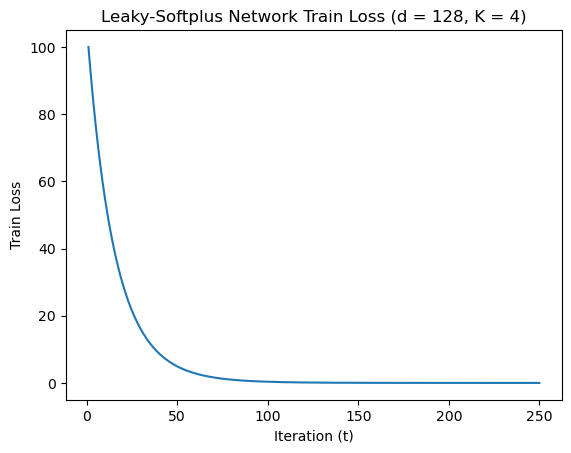

In [11]:
trials = 1

weight_decomp_norms = np.zeros((trials, epochs, 4))
weight_decomp_dists = np.zeros((trials, epochs - 1, 4))
train_losses = np.zeros((trials, epochs))

for i in range(trials):
    # Create data
    train_loader, val_loader, X, Y = get_data(d, K, N_k, scale, nu, normalize_, orthogonalize_, whiten_)

    print("=== TRIAL " + str(i) + " ===")
    
    # Train model
    weights, grads, outs, train_losses_trial = train_model(L, d, m, K, act_fn_str, 
                                                     train_loader, 
                                                     val_loader, 
                                                     epochs, 
                                                     lr, 
                                                     freq, 
                                                     loss_fn, 
                                                     optimizer_type=optimizer_type,
                                                     freeze_last_layer=freeze_last_layer, 
                                                     residual=residual,
                                                     batchnorm=batchnorm,
                                                     init_method=init_method,
                                                     init_scale=init_scale)


    # Plot train loss
    plot_train_losses(train_losses_trial, act_fn_str, d, d, K, None, savefig=False)
    train_losses[i, :] = train_losses_trial

    # Calculate norms of decompositions
    trial_decomp_norms, trial_decomp_dists = weight_decomp_norms_dists(weights, grads, K, init_scale, epochs)

    weight_decomp_norms[i, ...] = trial_decomp_norms
    weight_decomp_dists[i, ...] = trial_decomp_dists

In [12]:
print(np.linalg.cond(X))

1.3010230778334317


In [13]:
W1_0 = weights[0][0]
W2 = weights[0][1]
out0 = outs[0].T

G1_0 = grads[0][0]

D2_0 = out0 - Y
D1_0 = (W2.T @ D2_0) * d_leaky_softplus(W1_0 @ X)
_, s, V = svd_(D1_0)

#orthcomp_null_XV = svd_(X @ V @ np.diag(np.sqrt(s)), full_matrices=True)[0][:, :K]
orthcomp_null_G1_0 = svd_(G1_0)[-1][:, :K] # Orthogonal complement of "null space" of G1_0 (U1)
orthcomp_null_G1_W1_0 = svd_(G1_0.T @ W1_0 / init_scale)[-1][:, :K] # Orthogonal complement of "null space" of G1_0.T @ W1_0 (U2)


# Get basis for orthogonal complement of (U1 + U2) ==> (U1_perp) and (U2_perp)
V_null = orthcomp_intersection(orthcomp_null_G1_0, orthcomp_null_G1_W1_0) 
#V_null = orthcomp_intersection(orthcomp_null_XV, orthcomp_null_G1_W1_0) 
U_null = W1_0 @ V_null / init_scale

#return U_null, V_null

In [17]:
s1_X = np.linalg.norm(X, ord=2)


W1_0 = weights[0][0]
W2 = weights[0][1]
G1_0 = grads[0][0]
out0 = outs[0].T
D2_0 = out0 - Y
D1_0 = (W2.T @ D2_0) * d_leaky_softplus(W1_0 @ X)

s1_W2 = np.linalg.norm(W2, ord=2)
sK_W2 = np.linalg.svd(W2, compute_uv=False)[-1]

# print(np.linalg.cond(X))
# print(np.linalg.cond(W2), "\n")

sK_W2YX = np.linalg.svd(W2.T @ Y @ X.T, compute_uv=False)[K - 1]

d_phi_0 = d_leaky_softplus(0)
d2_phi_0 = d2_leaky_softplus(0)
mu = 0.25

# L0, s0, R0 = np.linalg.svd(G1_0, full_matrices=True)
# L0_2 = L0[:, K:]
# R0_2 = R0[K:, :].T

L0, s0, R0 = np.linalg.svd(G1_0, full_matrices=True)

U_null, V_null = small_update_subspace(W1_0, G1_0, K, init_scale)
p = U_null.shape[-1]

U_update = np.linalg.svd(U_null, full_matrices=True)[0][:, p:d]
V_update = np.linalg.svd(V_null, full_matrices=True)[0][:, p:]

D2_0_null = np.linalg.svd(D2_0, full_matrices=True)[-1][K:, :].T


D1_t_max_sum = np.max(np.abs(D1_0))
for t in range(1, epochs):
    W1_t = weights[t][0]
    Z1_t = W1_t @ X
    out = outs[t].T
    D2_t = out - Y
    D1_t = (W2.T @ D2_t) * d_leaky_softplus(W1_t @ X) 
    G1_t = grads[t][0]
    G1_t_an = D1_t @ X.T
    
    W1_t_X_max = np.max(np.abs(W1_t @ X))
    W1_t_max = np.max(np.abs(W1_t))
    
    Lt, st, Rt = np.linalg.svd(G1_t, full_matrices=True)
    D1_t_max_sum += np.max(np.abs(D1_t))
    
    print(D1_t_max_sum, "\n")
    
    
    #print(np.linalg.norm(G1_t @ V_update)**2 / (d - 2*K))
    #print(np.linalg.norm(G1_t @ V_null)**2 / (d - 2*K), "\n")
    
    #print(np.linalg.norm(G1_t @ V_null)**2 / (d - 2*K), "\n")
    
#     bound = mu * s1_W2 * s1_X * np.max(np.abs(W1_t @ X)) * np.sqrt(train_losses_trial[t])
#     print("bound = ", bound)
#     print("truth = ", st[K], "\n")
    


1.01001590167085 

1.4993030134368723 

1.978982069894852 

2.449151075104393 

2.9099138128388495 

3.3613768397237256 

3.803652551515968 

4.236856430434478 

4.661107143485038 

5.0765267800695995 

5.483238768492138 

5.881369505210654 

6.271046829037188 

6.652400111269389 

7.0255600763568395 

7.390657849687938 

7.7478257036615235 

8.097195868061911 

8.438902066835196 

8.773077175888758 

9.099853447652809 

9.419363420006034 

9.731739703800077 

10.03711359705563 

10.335615332612306 

10.627375921097023 

10.912523594519628 

11.191186740416931 

11.463491976448047 

11.72956491141279 

11.989530027174176 

12.243890501069039 

12.493561514779763 

12.738620318638892 

12.97914416592423 

13.215208748431394 

13.446889470224166 

13.674260239601606 

13.89739442662871 

14.116363876208114 

14.331240212279281 

14.54209372519087 

14.748993871817868 

14.952009209290042 

15.15120747625663 

15.346655269079307 

15.53841785160051 

15.726560420607932 

15.91114668056711

In [ ]:
# Mean and stdev of weight decomposition norms across trials
mean_weight_decomp_dists = np.mean(weight_decomp_dists, axis=0)
std_weight_decomp_dists = np.std(weight_decomp_dists, axis=0) 

mean_weight_decomp_norms = np.mean(weight_decomp_norms, axis=0)
std_weight_decomp_norms = np.std(weight_decomp_norms, axis=0) 


# Plotting
x_range = np.arange(1, epochs)
plt.figure(figsize=(8, 5))

# Plot each layer
for j in range(4):
    # Plot normalized distance from initialization
    plt_label = r'$\widetilde{W}_{1,' + str(j + 1) + r'}(t)$'
    plt.plot(x_range, 
               mean_weight_decomp_dists[:, j], 
               linewidth=3,
               label=plt_label)

    plt.fill_between(x_range, 
                     mean_weight_decomp_dists[:, j] - std_weight_decomp_dists[:, j], 
                     mean_weight_decomp_dists[:, j] + std_weight_decomp_dists[:, j],
                     linewidth=3,
                     alpha=0.5)






# Show figure 
title = r'$d > N$' if d > N else r'$N > d$'
plt.title(title, fontsize=24, y=1.15)
plt.xlabel('Train Epoch', fontsize=24)
plt.ylabel('Normalized Distance', 
              fontsize=24,
             x = 0.01)

plt.grid('on')
plt.xticks(fontsize=16) 
plt.yticks(fontsize=16)


plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.2), 
    ncol=4,
    fontsize=16,
    frameon=False
)

savefig_dir = './figs/verify_theory/'
if not os.path.exists(savefig_dir):
    os.makedirs(savefig_dir)

plt.tight_layout()
save_fname = 'verify_theory_large_d.pdf' if d > N else 'verify_theory_large_N.pdf'

#plt.savefig(os.path.join(savefig_dir, save_fname), bbox_inches='tight')
plt.show()
plt.close()